# MODELIZACIÓN

## IMPORTAR PAQUETES

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import janitor
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import RFE
from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## IMPORTAR LOS DATOS

Cargar los datos

In [54]:
x = pd.read_pickle('../02_datos/03_Entrenamiento/x_preseleccionado.pkl')
y = pd.read_pickle('../02_datos/03_Entrenamiento/y_preseleccionado.pkl')

## MODELIZANDO PARA UN PRODUCTO

In [55]:
x = x.loc[(x.store_id == 'CA_3') & (x.item_id == 'FOODS_3_586')]

Al filtrar x por tienda y producto, x se queda con menos filas, pero sigue conteniendo todas las originales. Con este ajuste filtro y me quedo solo con las filas cuyos índices están en x, de modo que ambos DataFrames tengan las mismas filas.

In [56]:
# Filtrar y para quedarnos solo con las filas de la tienda y producto seleccionados (mismos índices que x)
y = y[y.index.isin(x.index)]


### Modelizar

#### Definiar las variables

In [57]:
var_modelizar = x.columns.to_list()[3:]

#### Definir la validación

Partimos los datos en 3 bloques para predecir los siguientes 8 días. En cada prueba, el train cuenta con más datos que en la anterior para aprender, y el test siempre son los 8 días posteriores.

```text
Días:     1 ............................................ 30
Prueba 1: [train 1-6][test 7-14]
Prueba 2: [train 1-14        ][test 15-22]
Prueba 3: [train 1-22                    ][test 23-30]


In [58]:
time_cv = TimeSeriesSplit(3, test_size = 8)

#### Crear el pipeline y el diccionario de algoritmos, parámetros y valores a testar

Modificar para dejar solo los algoritmos que se quieran testar

Modificar los parámetros

In [59]:
pipe = Pipeline([('algoritmo', HistGradientBoostingRegressor())])

grid = [
    {
        'algoritmo': [HistGradientBoostingRegressor()],
        #'algoritmo__learning_rate': [0.01, 0.025, 0.05, 0.1],
        #'algoritmo__max_iter': [300, 500, 800],
        #'algoritmo__max_depth': [3, 5, 10]  
    }
]

#### Optimizar los hiperparámetros

##### Con random search 

In [60]:
random_search = RandomizedSearchCV(estimator = pipe,
                                   param_distributions = grid,
                                   n_iter = 1,
                                   cv = time_cv,
                                   scoring = 'neg_mean_absolute_error',
                                   verbose = 0,
                                   n_jobs = -1
)

modelo = random_search.fit(x[var_modelizar], y)

c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [61]:
modelo_final = modelo.best_estimator_.fit(x[var_modelizar], y)

c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [62]:
prediccion = modelo_final.predict(x[var_modelizar])

In [65]:
temp = pd.concat([x.date.reset_index(drop=True), 
                  y.reset_index(drop=True), 
                  pd.Series(prediccion, name = 'prediccion')], axis =1
                  )

In [66]:
temp

,date,ventas,prediccion
0,2013-01-16,6,6.874
1,2013-01-17,13,10.557
2,2013-01-18,8,10.718
3,2013-01-19,13,12.685
4,2013-01-20,13,12.100
...,...,...,...
1044,2015-11-26,14,11.935
1045,2015-11-27,10,10.525
1046,2015-11-28,6,7.570
1047,2015-11-29,7,5.967


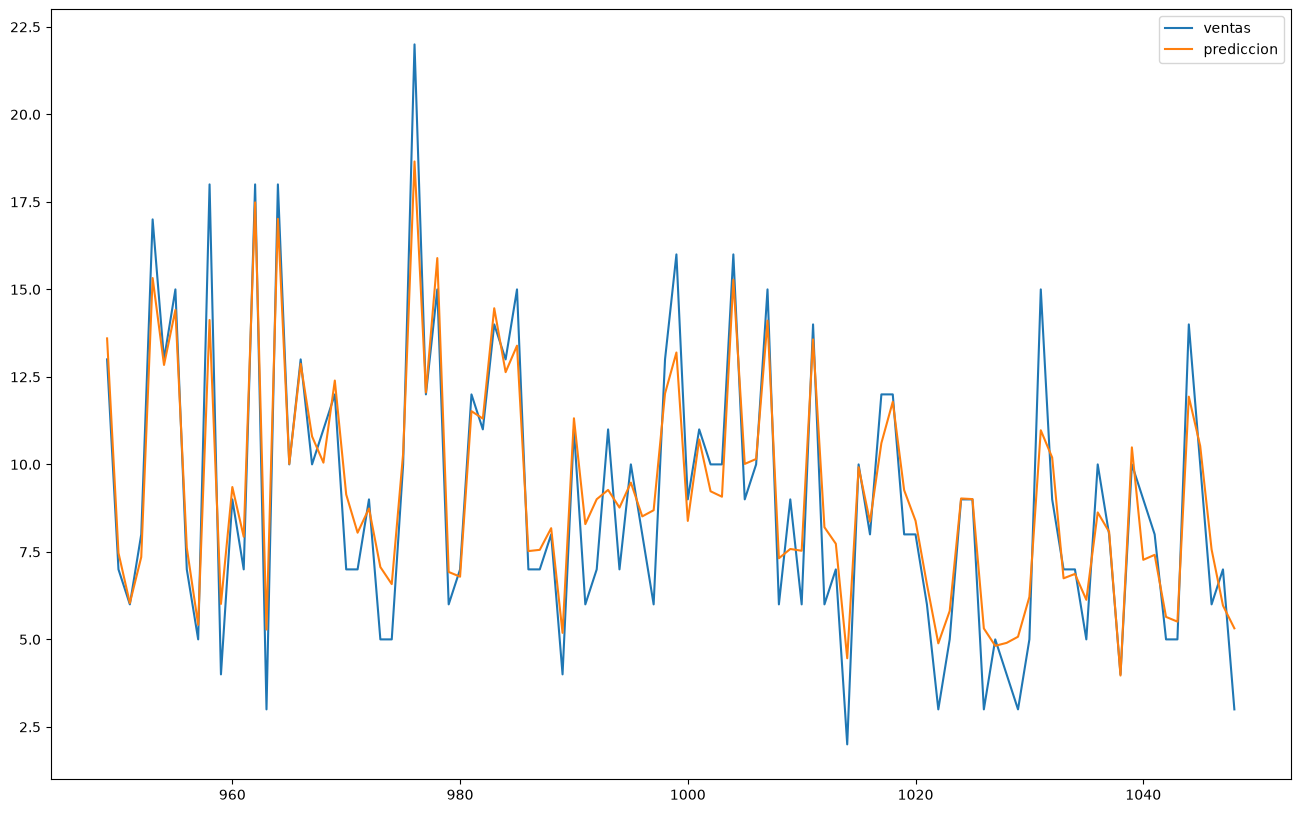

In [68]:
temp.tail(100).plot(figsize= (16,10));

## ESCALAR A TODOS LOS PRODUCTOS

### MODELIZACIÓN

- Despues de tener todo el codigo funcionando 
- Hay que escalar a todas las combinaciones de tienda y producto
- Primero volver a cargar los datos

In [69]:
x = pd.read_pickle('../02_datos/03_Entrenamiento/x_preseleccionado.pkl')
y = pd.read_pickle('../02_datos/03_Entrenamiento/y_preseleccionado.pkl')

Incluyo como una nueva variable la combinación de tienda-producto y elimino las demas

In [70]:
x.insert(loc=0, column='producto', value=x.store_id+'_'+x.item_id)
x = x.drop(columns= ['item_id', 'store_id'])
x.head()

,producto,date,ventas_mm_8,ventas_mm_7,ventas_mm_6,ventas_mm_9,ventas_mm_2,ventas_mm_10,ventas_mm_3,ventas_mm_5,...,rotura_stock_7_lag_1,rotura_stock_15_lag_1,weekday_te,month_te,event_name_1_ColumbusDay,event_name_1_StPatricksDay,wday_te,year_2013,event_name_1_IndependenceDay,event_type_1_Cultural
0,CA_3_FOODS_3_090,2013-01-16,233.375,236.000,242.500,228.333,182.000,232.500,215.000,242.000,...,0.000,0.000,24.894,25.394,0.000,0.000,24.894,1.000,0.000,0.000
1,CA_3_FOODS_3_090,2013-01-17,230.375,235.143,233.500,228.667,174.500,224.600,185.000,237.400,...,0.000,0.000,26.096,25.394,0.000,0.000,26.096,1.000,0.000,0.000
2,CA_3_FOODS_3_090,2013-01-18,227.000,224.429,226.167,223.667,180.500,222.800,173.000,201.200,...,0.000,0.000,29.476,25.394,0.000,0.000,29.476,1.000,0.000,0.000
3,CA_3_FOODS_3_090,2013-01-19,224.375,225.857,205.000,226.667,197.000,223.700,195.000,189.800,...,0.000,0.000,34.801,25.394,0.000,0.000,34.801,1.000,0.000,0.000
4,CA_3_FOODS_3_090,2013-01-20,242.875,227.429,218.500,239.667,293.000,240.200,252.000,221.000,...,0.000,0.000,34.385,25.394,0.000,0.000,34.385,1.000,0.000,0.000


Para poder aplicar el proceso de forma recurrente vamos a crear una lista donde cada elemento sean los datos de cada producto.

In [75]:
productos = list(x.groupby('producto'))

Encapsulo el proceso de modelización individual en una función, a la que iremos llamando en cada producto

In [83]:
# Recibimos los datos de las x y las y de cada producto

def modelizar(x_producto, y):

    # Excluye el producto como variable de modelización
    var_modelizar = x_producto.columns.to_list()[2:]

    # Define la validación cruzada
    time_cv = TimeSeriesSplit(3, test_size = 8)

    # Define los algoritmos
    pipe = Pipeline([('algoritmo', HistGradientBoostingRegressor())])
    grid = [
        {
            'algoritmo': [HistGradientBoostingRegressor()],
            #'algoritmo__learning_rate': [0.01, 0.025, 0.05, 0.1],
            #'algoritmo__max_iter': [50, 100, 200],
            #'algoritmo__max_depth': [5, 10, 20, 50]
            #'algoritmo__scorting': ['neg_mean_absolute_error']
            #'algoritmo__12_regularization': [0, 0.25, 0.5, 0.75, 1]  
        }
    ]

    # Crea el modelo
    random_search = RandomizedSearchCV(estimator = pipe,
                                       param_distributions = grid,
                                       # Si se quiere hiperparametrizacion aqui hay que poner los párametros que se quieran
                                       n_iter = 1,
                                       cv = time_cv,
                                       scoring = 'neg_mean_absolute_error',
                                       verbose = 0,
                                       n_jobs = -1
                                       )

    modelo = random_search.fit(x_producto[var_modelizar], y)
    # Reentrena el mejor de todos los datos
    modelo_final = modelo.best_estimator_.fit(x_producto[var_modelizar], y)

    # Devuelve como salida el modelo final
    return(modelo_final)

Creamos otra lista vacía donde a ir guardando los modelos entrenados de cada producto

In [84]:
lista_modelos = []

Recorremos cada elemento de la lista de productos y la vamos rellenando lista_modelos con el nombre y modelo final de cada producto

In [85]:
for cada in productos:
    # Renombra por claridad
    producto = cada[0]
    datos = cada[1]

    # Selecciona solo los datos de la target que se corresponde con el producto
    y_cada = y[y.index.isin(datos.index)]

    # Llama a la función de modelizar
    modelo = modelizar(datos, y_cada)

    # Añade el modelo final a la lista
    lista_modelos.append((producto, modelo))

c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A colu

In [86]:
lista_modelos

[('CA_3_FOODS_3_090',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_120',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_202',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_252',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_288',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_329',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_555',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_586',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_587',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_3_FOODS_3_714',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),
 ('CA_4_FOODS_3_090',
  Pipeline(steps=[('algoritmo', HistGradientBoostingRegressor())])),

Comprobamos

NOTA: No estamos evaluando la calidad del modelo ya que no estamos utilizando los datos de entrenamiento

- Solo quiero comprobar que el módelo funciona 

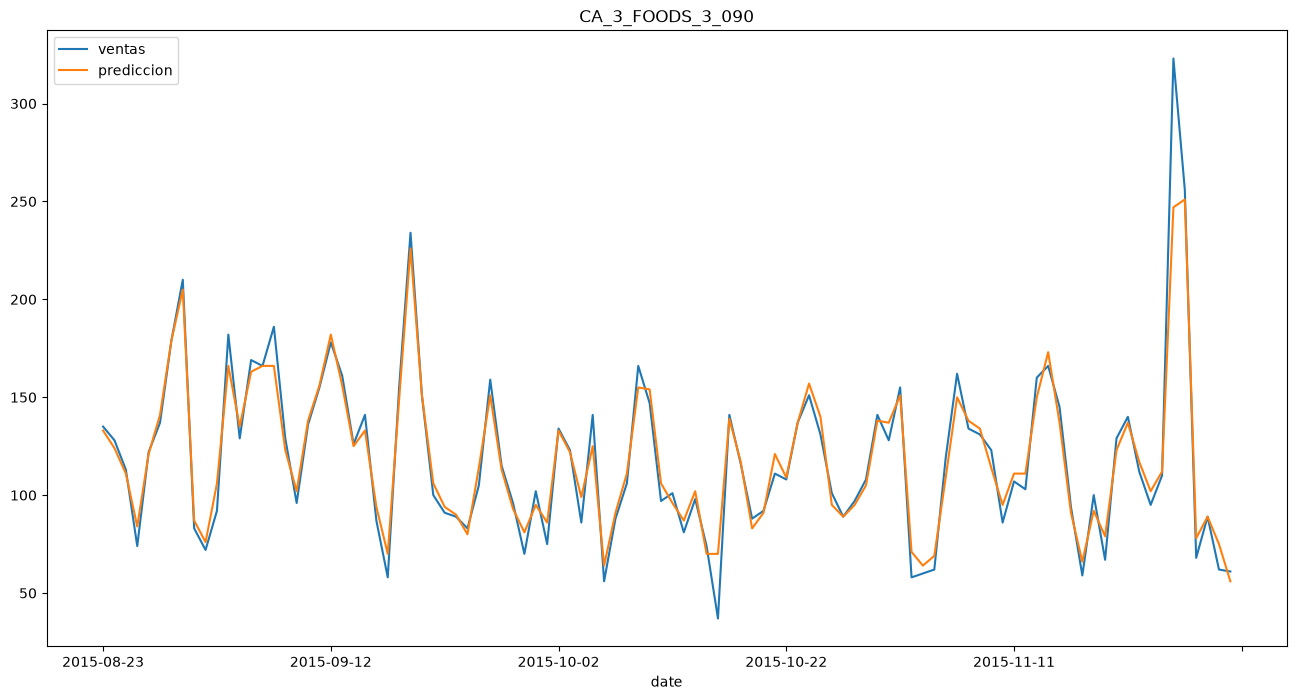

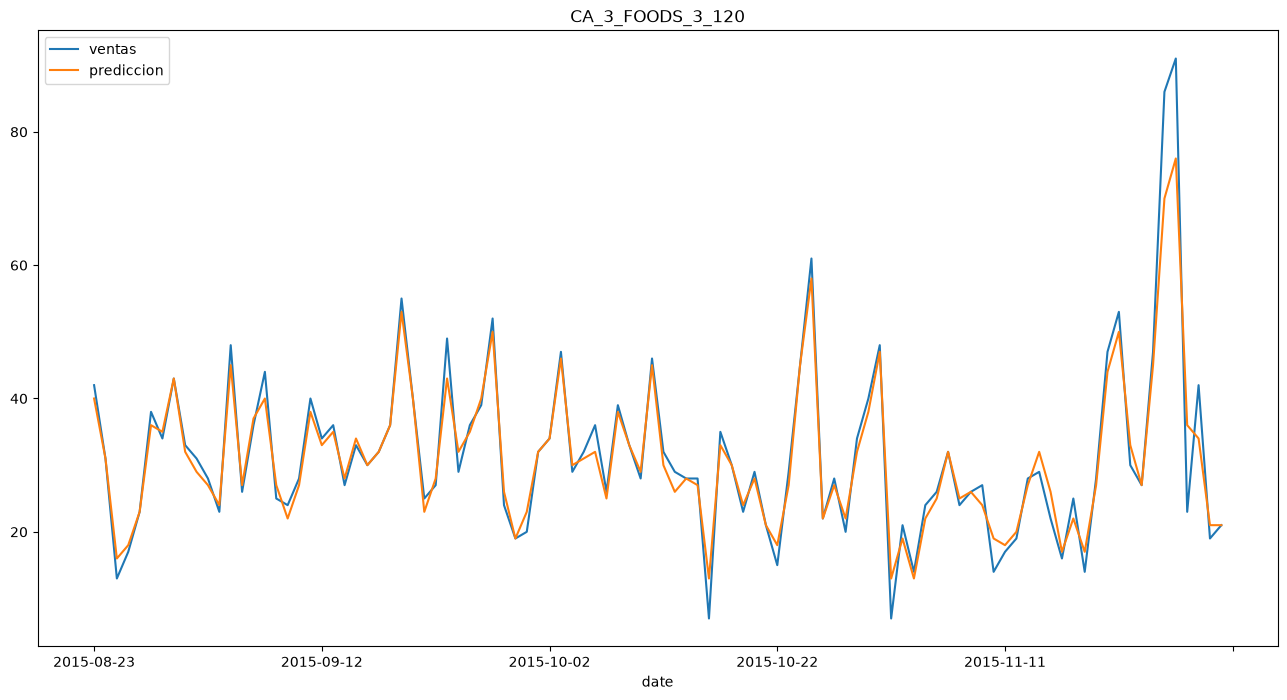

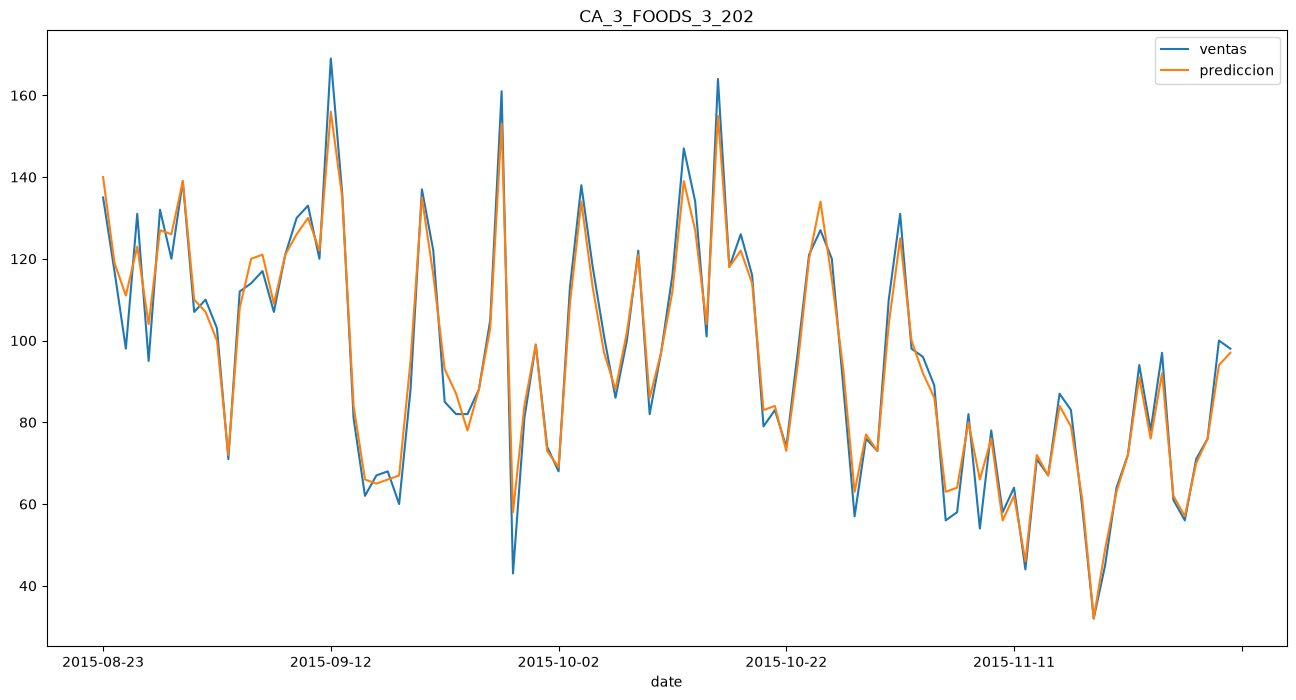

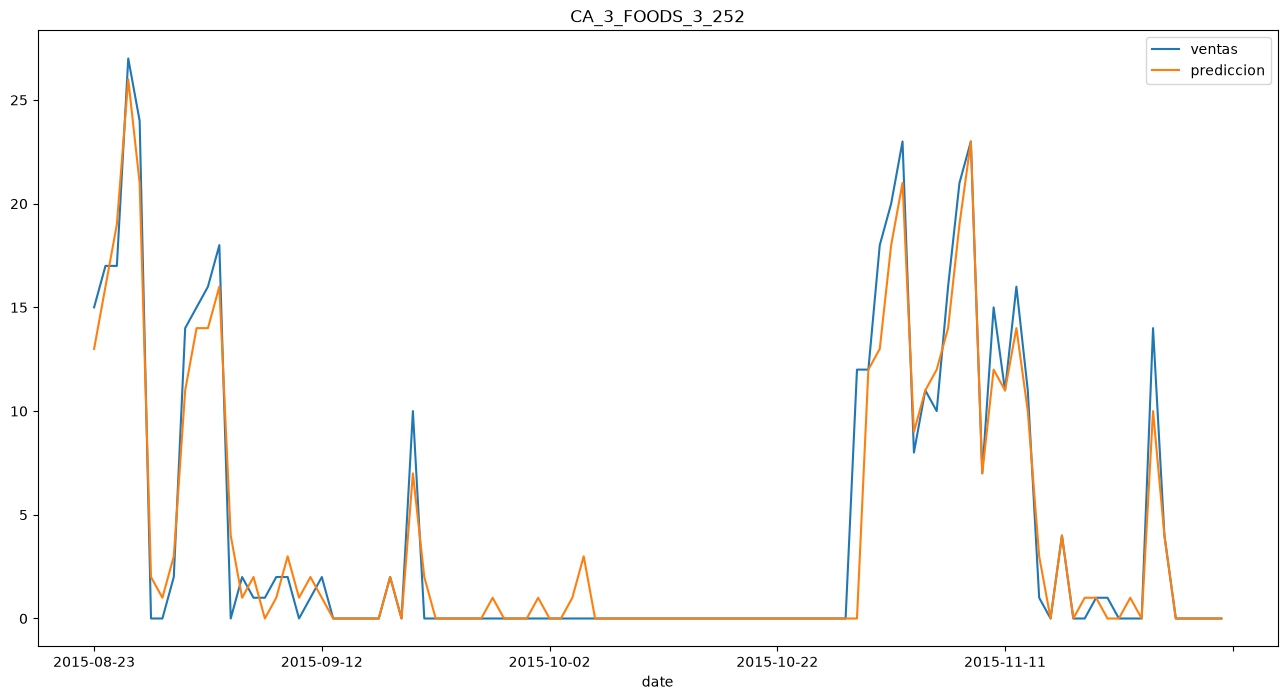

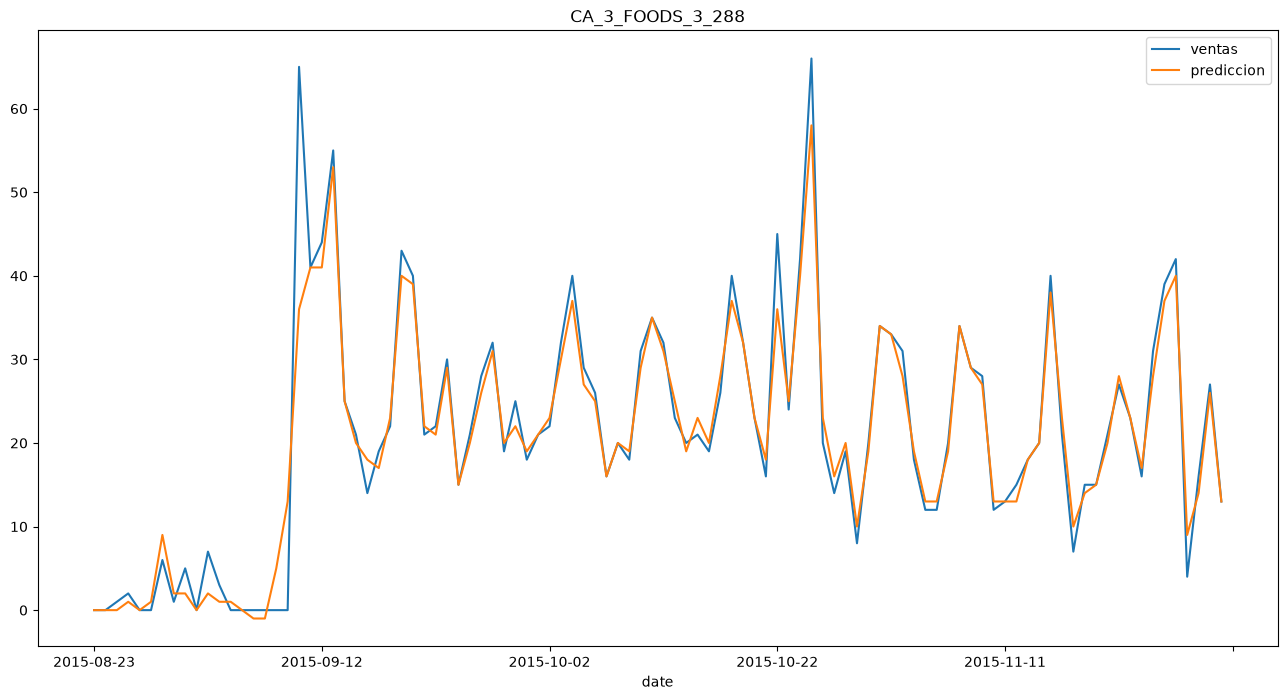

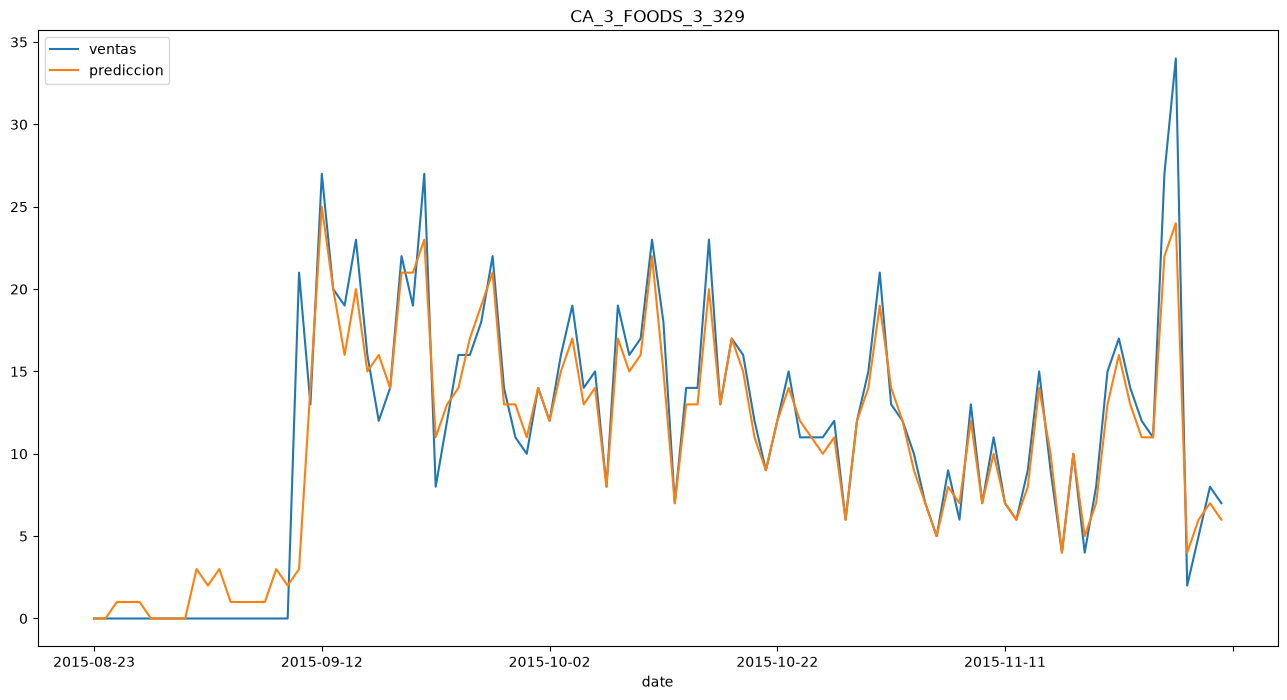

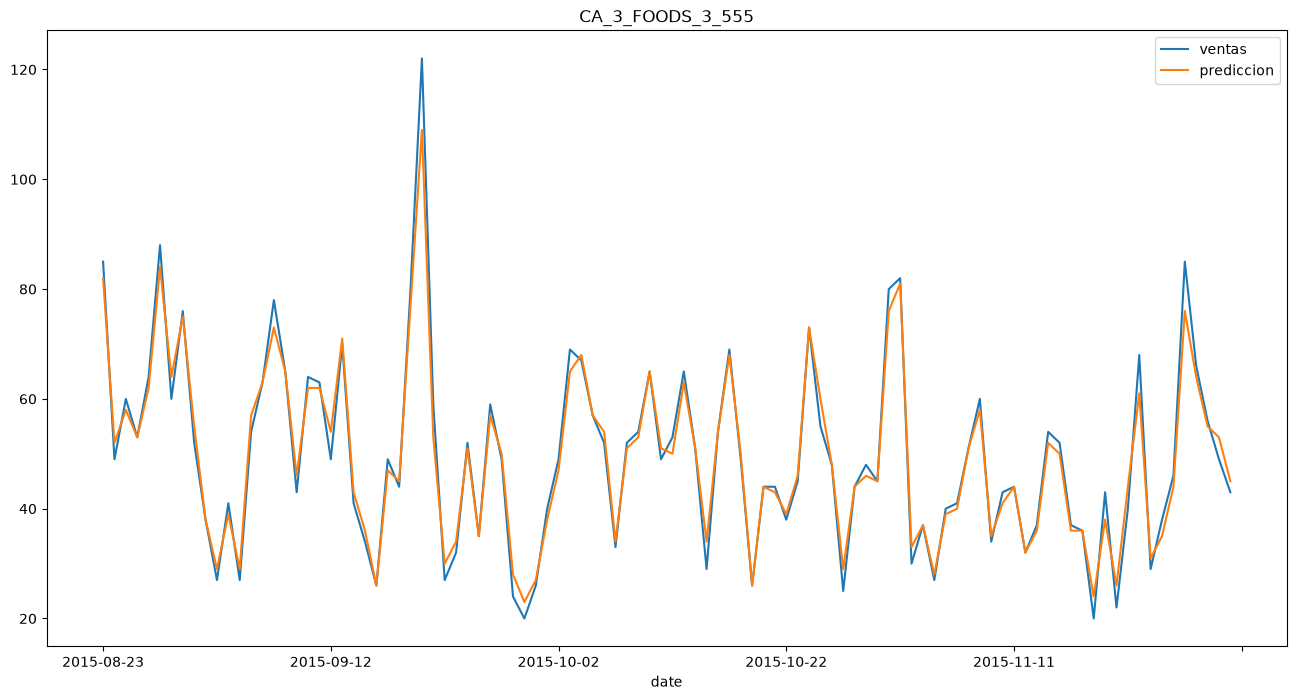

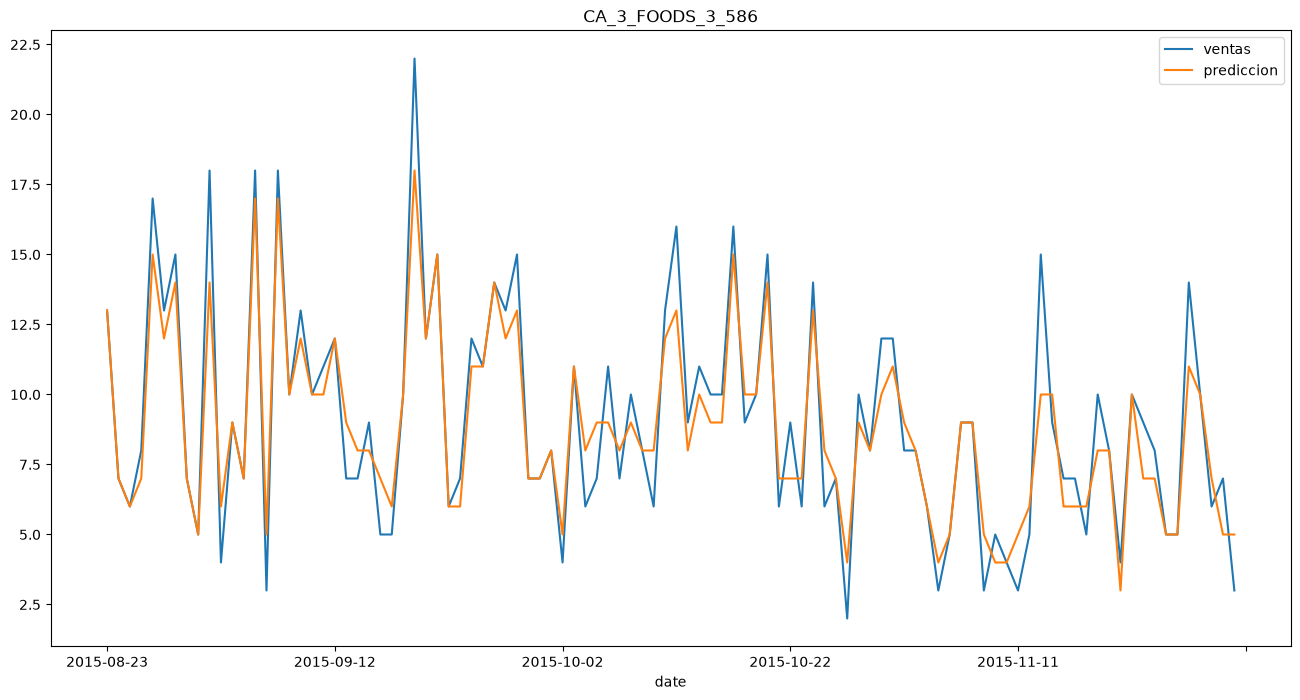

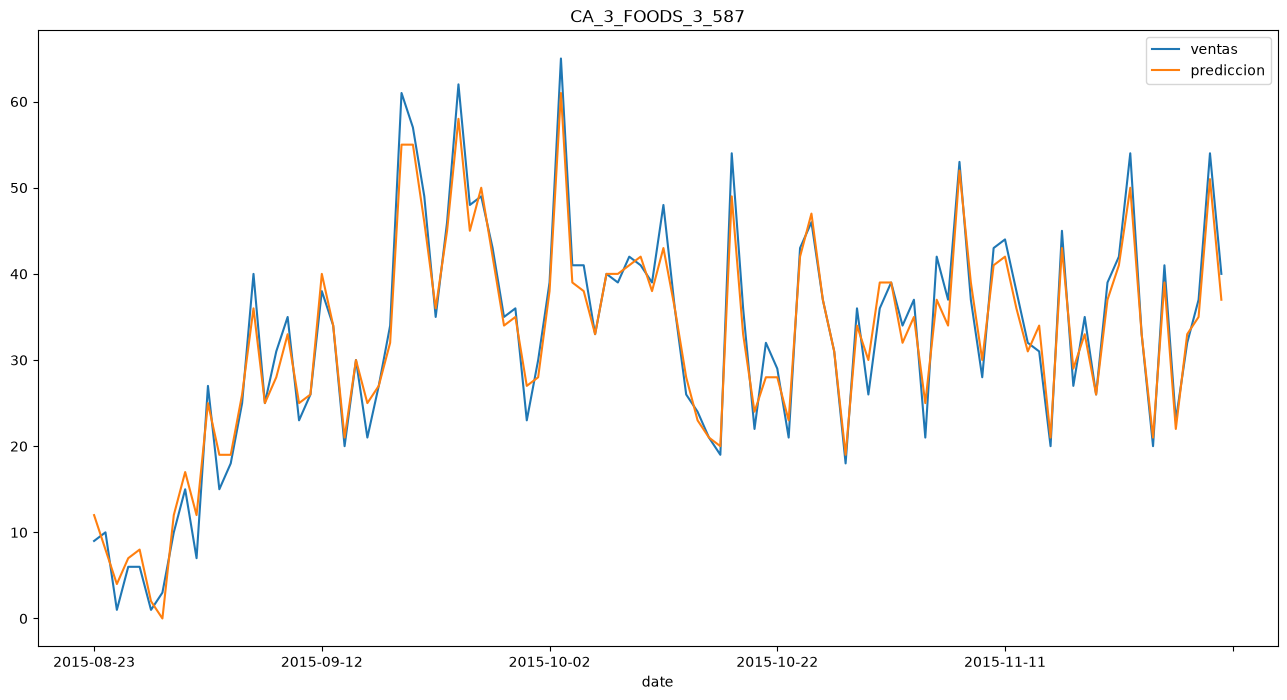

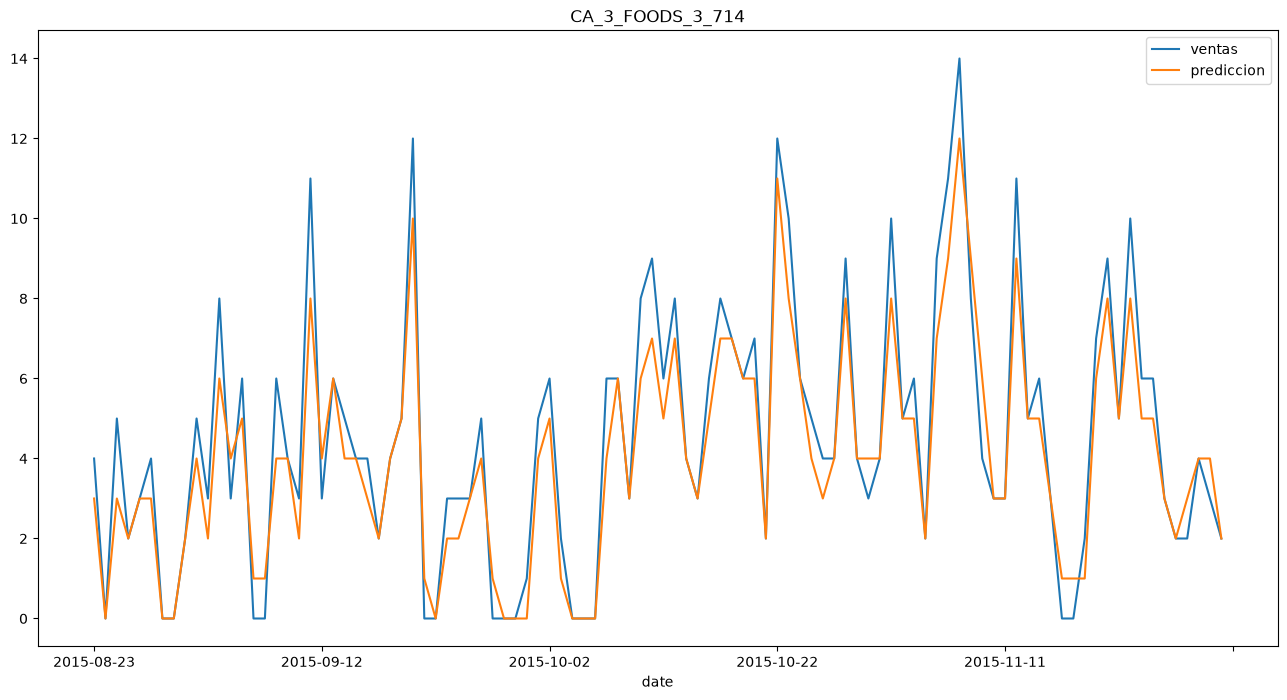

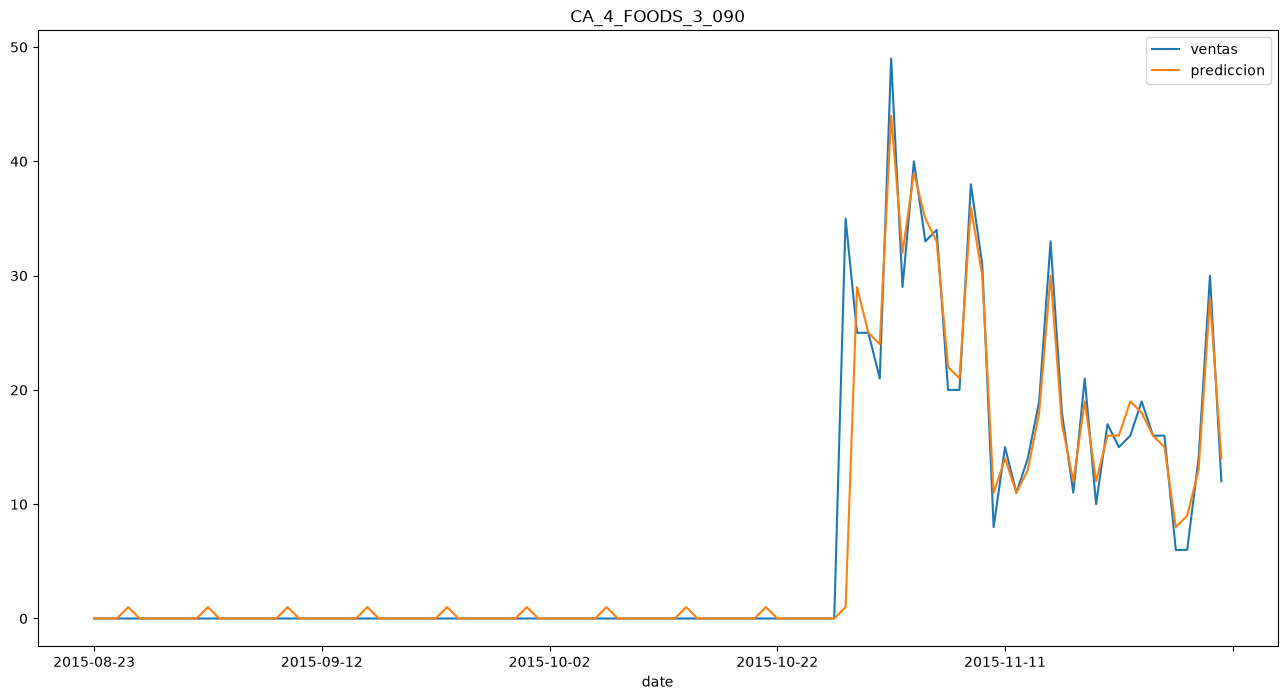

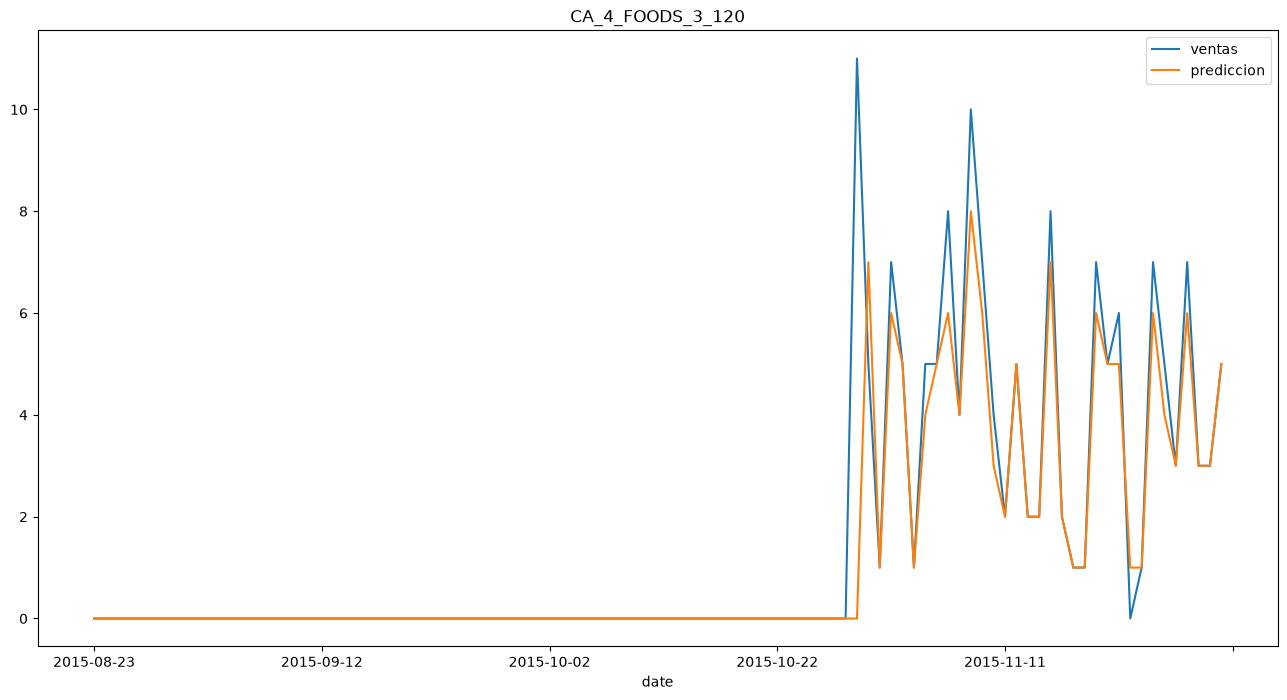

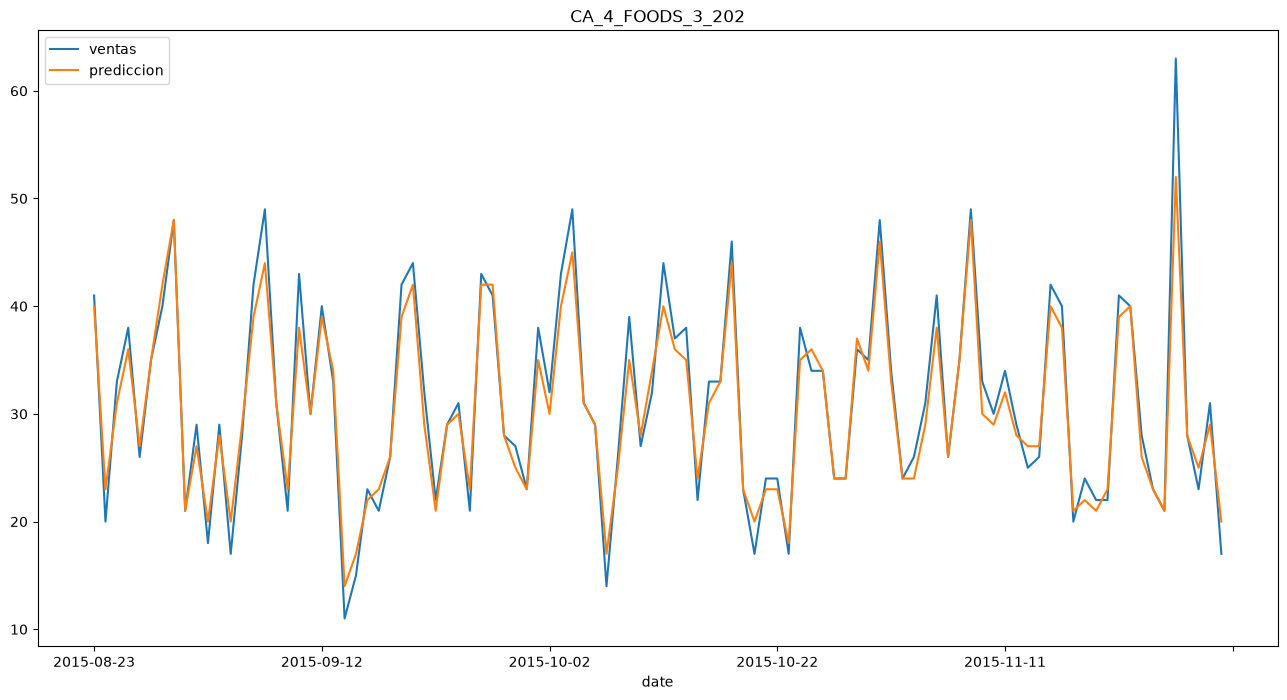

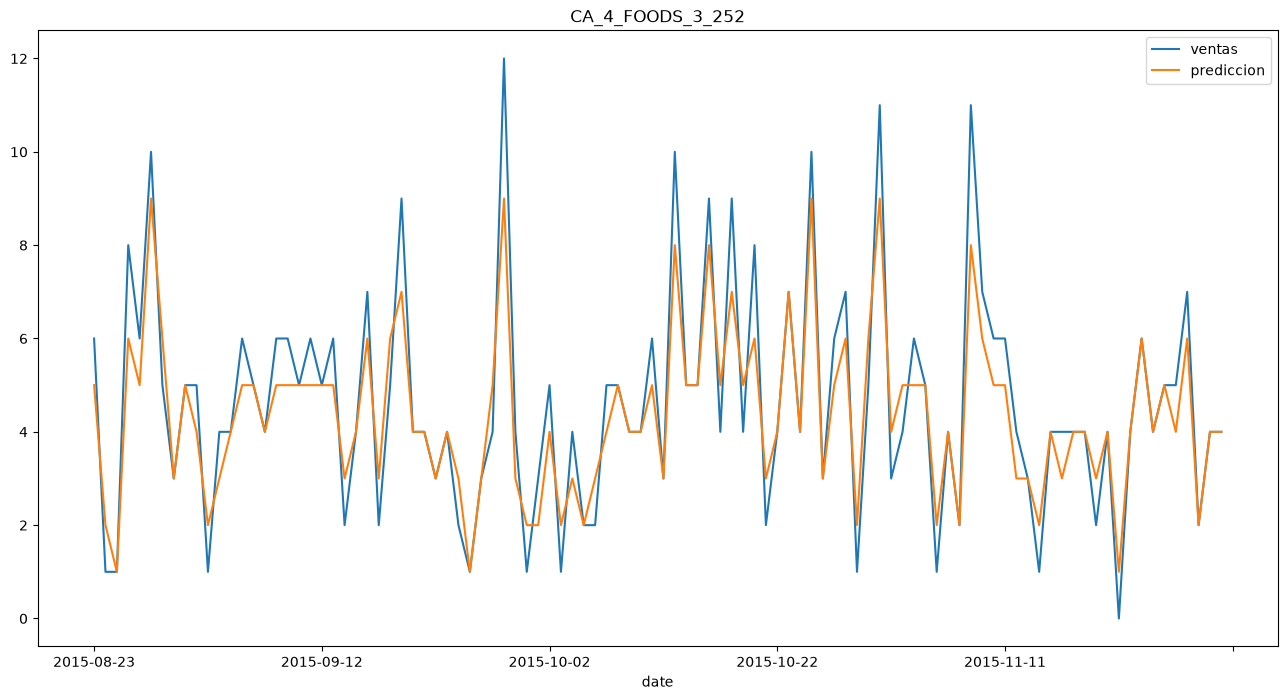

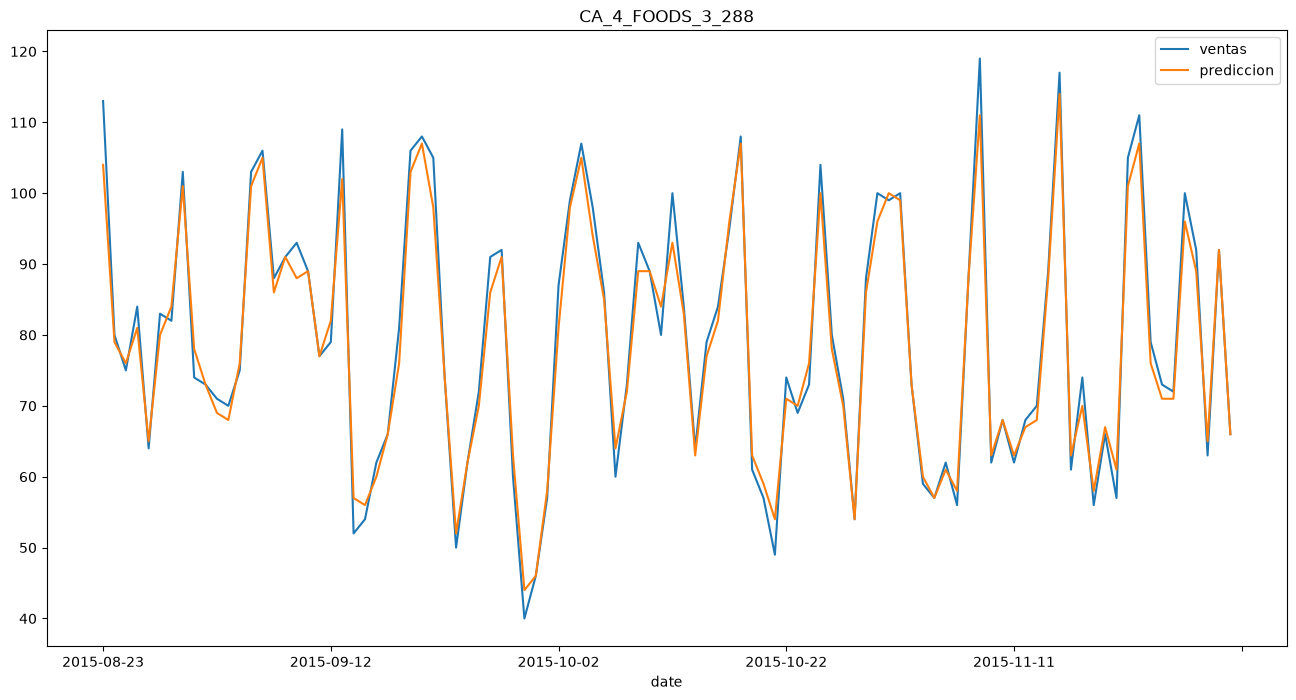

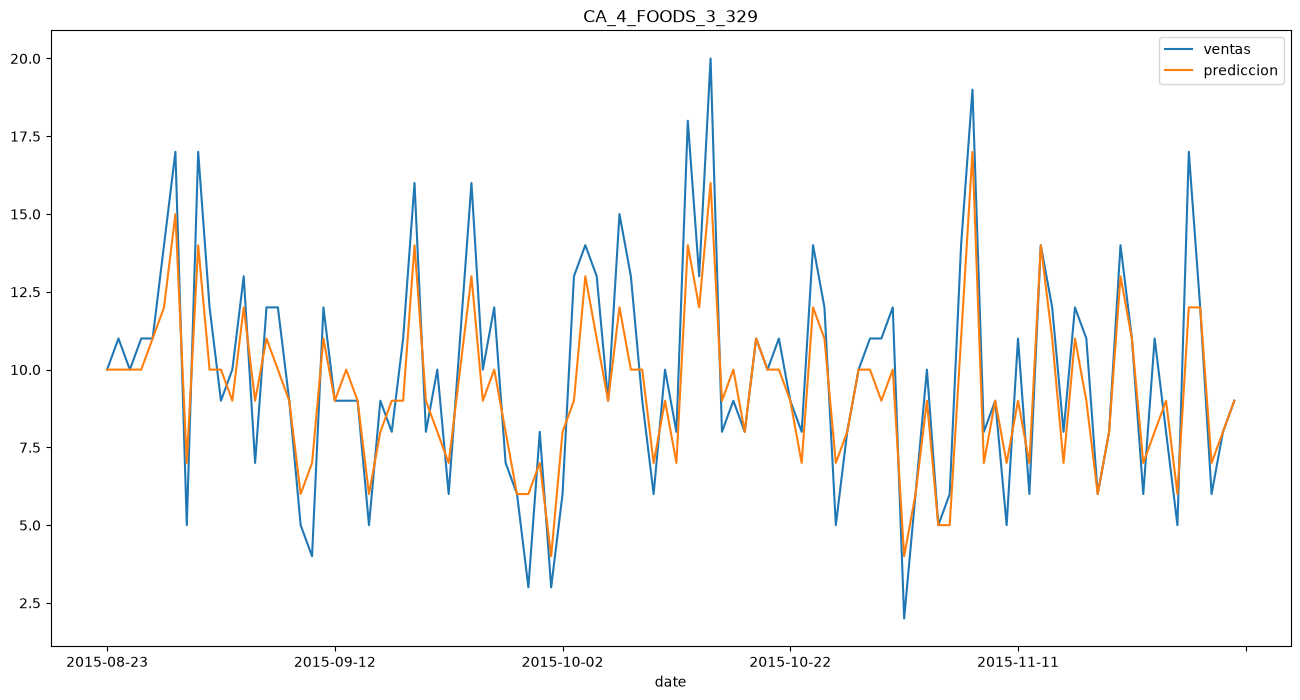

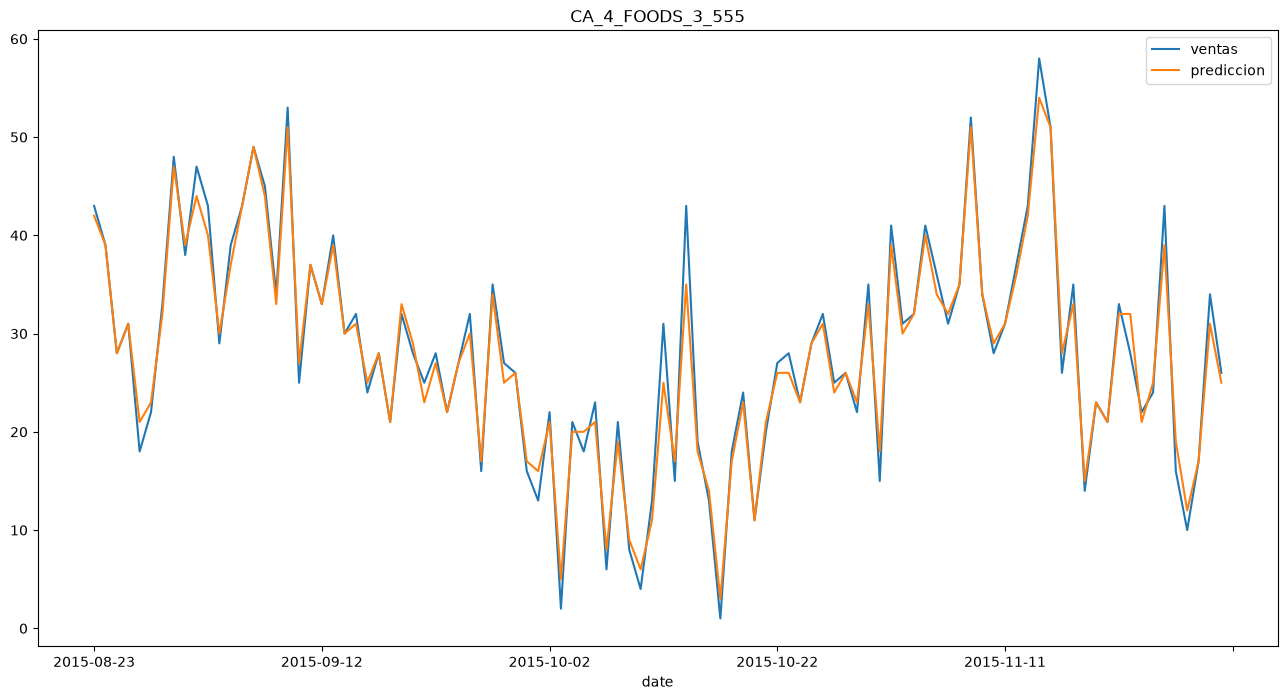

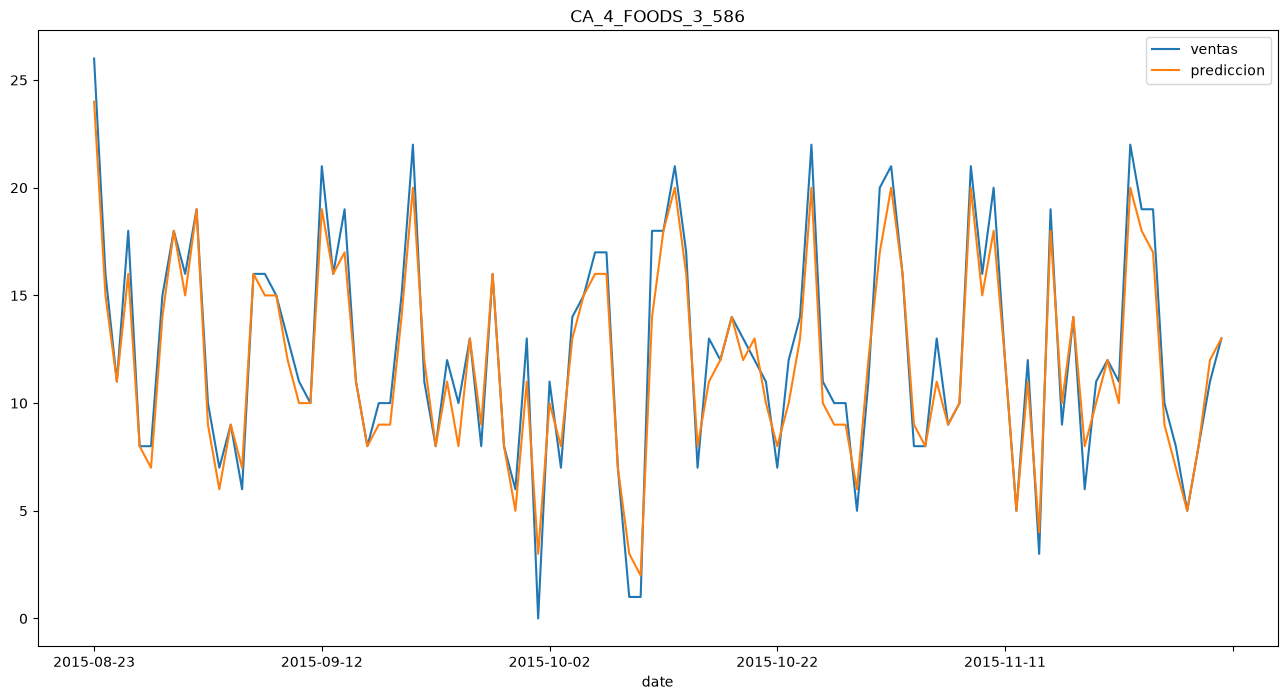

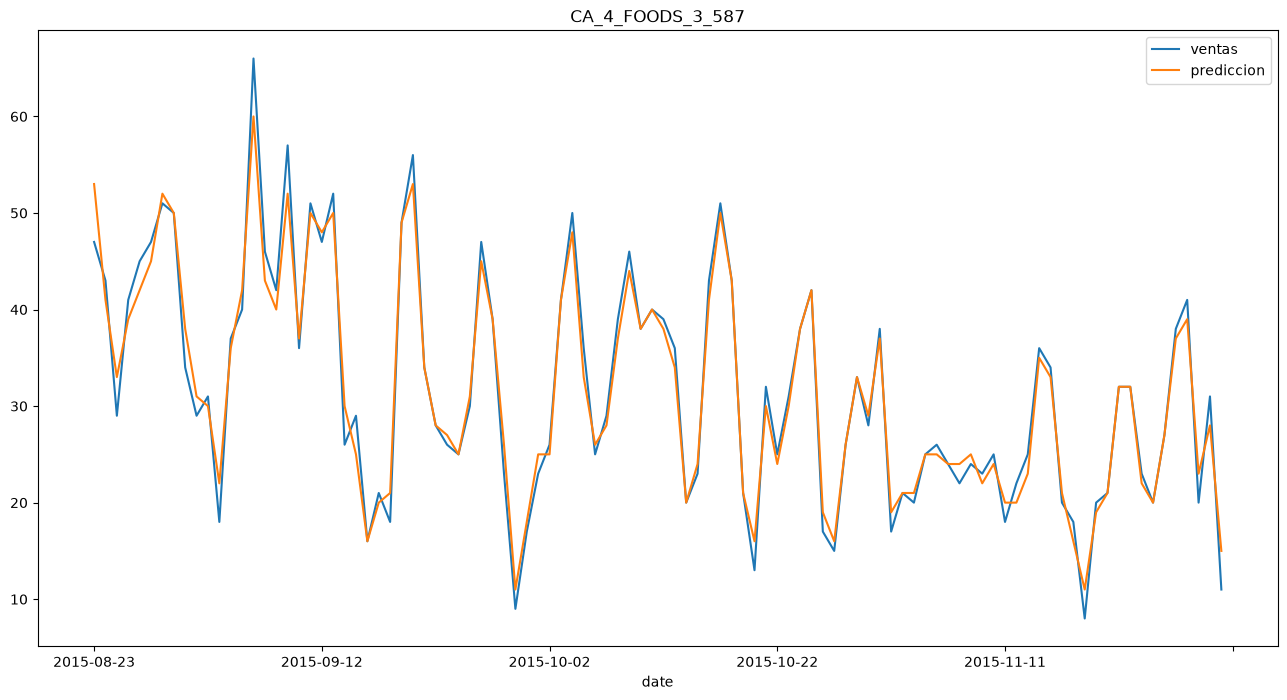

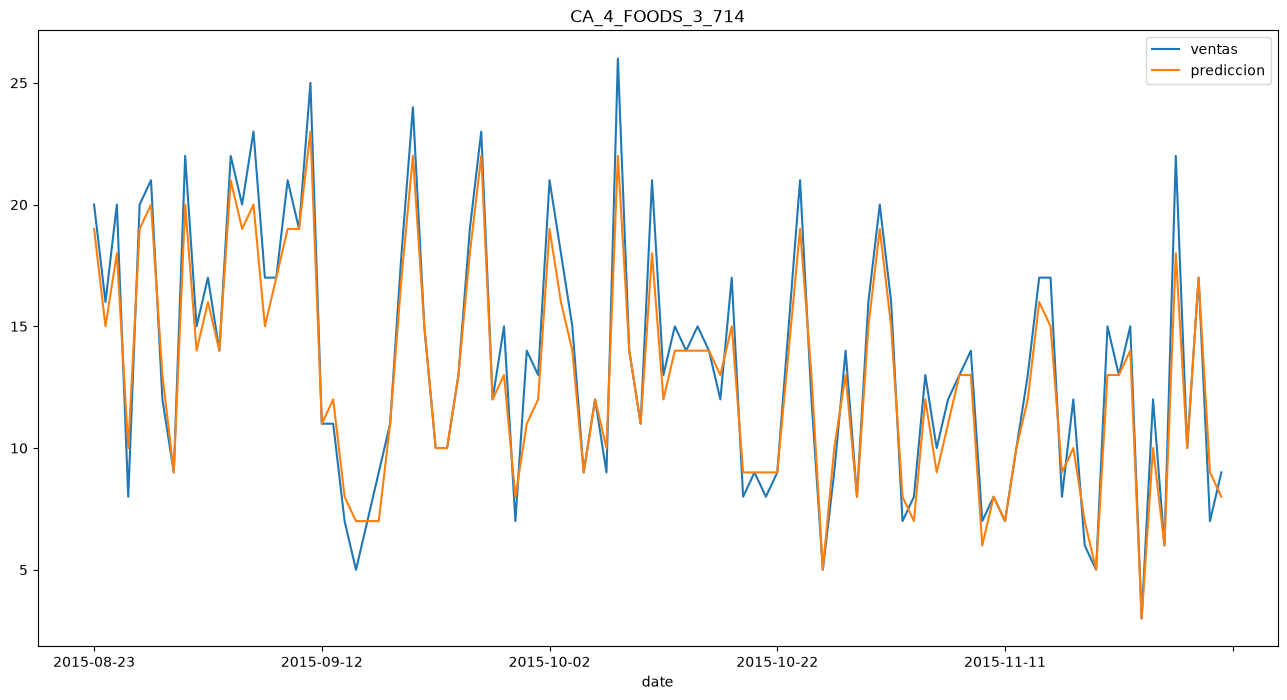

In [ ]:
# Unificar el df para poder extraer los datos de x e y de cada producto
df = pd.concat([x, y], axis=1)

for cada in range(0,len(lista_modelos)):

    # Prepara los datos necesarios
    producto = lista_modelos[cada][0]
    modelo = lista_modelos[cada][1]
    variables = modelo[0].feature_names_in_
    target = 'ventas'

    x_prod = df.loc[df.producto == producto].drop(columns=target).copy()
    y_prod = df.loc[df.producto == producto, 'ventas'].copy()

    date = x_prod.date.values

    # Genera gráficos de predicho vs real
    predicciones = pd.DataFrame(data= {'date' : date,
                                       'producto' : producto,
                                       'ventas' : y_prod,
                                       'prediccion' : modelo.predict(x_prod[variables])})

    predicciones['prediccion'] = predicciones.prediccion.astype('int')
    predicciones.set_index('date', inplace=True)
 
    predicciones.tail(100).plot(figsize= (16,8), title = producto);